# 1.2 - Regresión lineal simple y gradiente descendente: calorías

* En este notebook resolveremos un problema de **regresión**: estimar cuántas calorías quema una persona en función del tiempo que corre.
* Utilizaremos un **modelo de regresión lineal simple** y el **optimizador de gradiente descendente** para ajustar sus parámetros.
* Después visualizaremos el aprendizaje pulsando un botón para ejecutar **un epoch cada vez**.

1. Modelo y optimizador.
2. Función de pérdida y métricas.
3. Gradiente descendente.
4. Datos de calorías y tiempo.
5. Entrenamiento interactivo.

---
# 1. Modelo y optimizador

* Queremos estimar las **calorías quemadas** a partir de los **minutos que una persona corre**. La variable de entrada es $x = \text{minutos}$ y la salida es $y = \text{calorías}$.
* Elegimos un **modelo** de regresión lineal simple. Su forma es una recta:

$$\widehat{\text{calorías}} = \beta_1 \cdot \text{minutos} + \beta_0$$

* $\beta_1$ es la **pendiente**: cuánto cambia la predicción cuando aumenta un minuto el tiempo de carrera. $\beta_0$ es el **término independiente**: la predicción del modelo cuando los minutos son cero.
* Antes de entrenar conocemos la **forma del modelo**, pero debemos encontrar valores apropiados para $\beta_1$ y $\beta_0$.

### ¿Qué hace el optimizador?

* El **optimizador de gradiente descendente** ajusta los valores de $\beta_1$ y $\beta_0$ para reducir la función de pérdida y conseguir una recta que se ajuste a los datos de entrenamiento.
* Por tanto, distinguimos **dos elementos**: el modelo define la forma de la predicción; el optimizador busca los valores de sus parámetros.
* En una **red neuronal** ocurre lo mismo: la arquitectura define la forma del modelo y sus parámetros incluyen pesos y sesgos. Un optimizador, como gradiente descendente, Adam o RMSprop, actualiza esos parámetros para reducir la pérdida.

---
# 2. Error, función de pérdida y métricas

* Para cada observación $i$, calculamos el **error** como la diferencia entre el valor predicho y el valor real:

$$e^{(i)} = \hat{y}^{(i)} - y^{(i)}$$

* Para evaluar el error de todas las observaciones podemos utilizar, entre otras, las siguientes métricas:

$$MAE = \frac{1}{N}\sum_{i=1}^{N}|\hat{y}^{(i)} - y^{(i)}|$$

$$MSE = \frac{1}{N}\sum_{i=1}^{N}(\hat{y}^{(i)} - y^{(i)})^2$$

* **MAE** es el error absoluto medio y se expresa en las mismas unidades que $y$.
* **MSE** es el error cuadrático medio, se expresa en unidades al cuadrado y da más peso a los errores grandes.
* En este ejemplo utilizaremos la siguiente **función de pérdida** para ajustar los parámetros:

$$E(\beta_0,\beta_1) = \frac{1}{N}\sum_{i=1}^{N}(\beta_0 + \beta_1 x^{(i)} - y^{(i)})^2 = MSE$$

* Utilizaremos el **MSE como función de pérdida**: el optimizador ajusta los parámetros para reducirlo. Mostraremos también el MAE para interpretar el error en las unidades de $y$.

---
# 3. Optimizador: Gradiente descendente

* El optimizador de gradiente descendente parte de unos valores iniciales para $\beta_0$ y $\beta_1$ y los modifica para reducir la función de pérdida del modelo de calorías.
* Para calcular la dirección de actualización obtenemos las derivadas parciales de $E$ respecto de cada parámetro:

$$\frac{\partial E}{\partial \beta_0} = \frac{2}{N}\sum_{i=1}^{N}e^{(i)}$$

$$\frac{\partial E}{\partial \beta_1} = \frac{2}{N}\sum_{i=1}^{N}e^{(i)}x^{(i)}$$

* Actualizamos ambos parámetros **a la vez**, utilizando los valores que tenían antes de la actualización:

$$\beta_0^{new}=\beta_0^{old}-\alpha\frac{\partial E}{\partial \beta_0} \qquad
\beta_1^{new}=\beta_1^{old}-\alpha\frac{\partial E}{\partial \beta_1}$$

* La forma de ajustar los valores de **$\beta_0$ y $\beta_1$** es derivar parcialmente la función de pérdida respecto a cada parámetro. Sustituyendo el error por su expresión, las actualizaciones quedan así:

$$\beta_1^{new} := \beta_1^{old} - \alpha\,\frac{2}{N}\sum_{i=1}^{N}\left((\beta_0^{old} + \beta_1^{old} x^{(i)}) - y^{(i)}\right)x^{(i)}$$

$$\beta_0^{new} := \beta_0^{old} - \alpha\,\frac{2}{N}\sum_{i=1}^{N}\left((\beta_0^{old} + \beta_1^{old} x^{(i)}) - y^{(i)}\right)$$

* El factor $2$ aparece porque la función de pérdida utilizada es el **MSE**, sin el factor $1/2$.

* $\alpha$ es el **learning rate** o tasa de aprendizaje. Controla el tamaño del paso: un valor muy pequeño puede hacer que el entrenamiento avance lentamente y uno demasiado grande puede provocar oscilaciones o divergencia.
* Aquí utilizaremos **batch gradient descent**: en cada epoch calculamos el gradiente con los N elementos y actualizamos los parámetros una vez. En entrenamiento con minibatches puede haber varias actualizaciones por epoch.

### Pseudocódigo

```text
Inicializar beta_0 y beta_1
Repetir para cada epoch:
    Calcular las predicciones y los errores de los N elementos
    Calcular los gradientes de beta_0 y beta_1
    Actualizar ambos parámetros simultáneamente
    Evaluar el modelo actualizado con MAE y MSE
```

---
# 4. Conjunto de datos: calorías y tiempo

* Cargamos el archivo `./datasets/calories_time_reduc.csv`.
* La columna **Time** contiene el tiempo de carrera en minutos y será la entrada $X$; la columna **Calories** contiene las calorías y será la salida $y$.
* Mostramos las cinco primeras observaciones y, después, una gráfica con **minutos en el eje X** y **calorías en el eje Y**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Leemos el conjunto de datos y seleccionamos las variables de entrada y salida.
dataset = pd.read_csv('./datasets/calories_time_reduc.csv')
X = dataset['Time'].to_numpy(dtype=float)
y = dataset['Calories'].to_numpy(dtype=float)

display(dataset.head())
print(f'Número de observaciones: {len(dataset)}')

,Calories,Time
0,0.0,0.0
1,177.9,13.7
2,644.1,51.9
3,929.4,55.4
4,941.2,61.9


Número de observaciones: 74


### Visualización del conjunto de datos

* Cada punto representa una observación: tiempo de carrera y calorías.

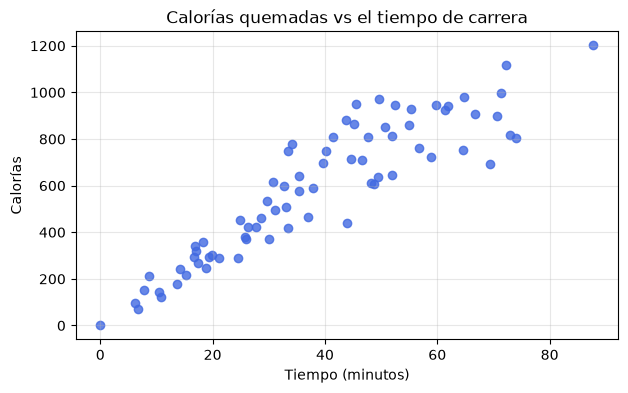

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X, y, color='royalblue', alpha=0.8)
ax.set_title('Calorías quemadas vs el tiempo de carrera')
ax.set_xlabel('Tiempo (minutos)')
ax.set_ylabel('Calorías')
ax.grid(alpha=0.3)
plt.show()

---
# 5. Implementación de un epoch

* La función `un_epoch` calcula las predicciones y errores con el modelo actual, obtiene los gradientes con todos los datos de calorías y tiempo y devuelve los parámetros actualizados.
* A continuación se calculan las métricas con **los mismos parámetros actualizados** que se muestran en la gráfica.

In [3]:
def un_epoch(X, y, beta_0, beta_1, alpha):
    """Realiza una actualización simultánea minimizando el MSE por lote."""
    predicciones = beta_0 + beta_1 * X
    errores = predicciones - y

    gradiente_beta_0 = 2 * np.mean(errores)
    gradiente_beta_1 = 2 * np.mean(errores * X)

    nuevo_beta_0 = beta_0 - alpha * gradiente_beta_0
    nuevo_beta_1 = beta_1 - alpha * gradiente_beta_1
    return nuevo_beta_0, nuevo_beta_1


def calcular_metricas(X, y, beta_0, beta_1):
    """Calcula MAE y MSE para el modelo indicado."""
    errores = beta_0 + beta_1 * X - y
    mae = np.mean(np.abs(errores))
    mse = np.mean(errores ** 2)
    return mae, mse

---
# 6. Entrenamiento interactivo

* Ejecuta las celdas anteriores en orden y después ejecuta la siguiente celda.
* Pulsa **«Ejecutar 1 epoch»** para calcular el gradiente con todas las observaciones y actualizar $\beta_1$ y $\beta_0$ una vez. Cada pulsación añade un punto a la evolución de MAE y MSE.
* El **epoch 0** representa el modelo inicial, antes de entrenar. Las métricas mostradas corresponden a la recta visible.
* Modifica **α** para cambiar la tasa de aprendizaje que se aplicará en la siguiente pulsación. Pulsa **«Reiniciar»** para volver a los parámetros iniciales; α se conserva.
* Como los minutos son mayores que los valores usados en el ejemplo anterior, empezamos con una tasa de aprendizaje más pequeña: **0,0001**. Si es demasiado alta, la pérdida puede crecer.

> MAE y MSE se calculan sobre los datos utilizados para entrenar. Para evaluar la generalización hay que reservar datos independientes.

In [4]:
# Configuración inicial: valores fijos para que el ejemplo sea reproducible.
ALPHA_INICIAL = 0.0001
BETA_0_INICIAL = 0.0
BETA_1_INICIAL = 0.0

estado = {'epoch': 0, 'beta_0': BETA_0_INICIAL, 'beta_1': BETA_1_INICIAL,
          'epochs': [], 'mae': [], 'mse': []}
boton_epoch = widgets.Button(description='Ejecutar 1 epoch', button_style='primary',
                             icon='step-forward', layout=widgets.Layout(width='180px'))
boton_reiniciar = widgets.Button(description='Reiniciar', icon='refresh',
                                 layout=widgets.Layout(width='130px'))
alpha = widgets.FloatText(value=ALPHA_INICIAL, description='α:', step=0.00001,
                          layout=widgets.Layout(width='180px'),
                          style={'description_width': '30px'})
alpha.add_class('tasa-aprendizaje')
estilo = widgets.HTML('<style>.tasa-aprendizaje input, .tasa-aprendizaje label {font-size: 19px !important;}</style>')
resumen = widgets.HTML()
salida_graficas = widgets.Output()


def registrar_metricas():
    mae, mse = calcular_metricas(X, y, estado['beta_0'], estado['beta_1'])
    estado['epochs'].append(estado['epoch'])
    estado['mae'].append(mae)
    estado['mse'].append(mse)


def actualizar_vista():
    resumen.value = (
        f"<div style='font-size: 19px; line-height: 1.8'><b>Epoch:</b> {estado['epoch']} &nbsp;&nbsp; "
        f"<b>Modelo:</b> calorías = {estado['beta_1']:.1f} · min + {estado['beta_0']:.1f} &nbsp;&nbsp; "
        f"<b>MAE:</b> {estado['mae'][-1]:.2f} &nbsp;&nbsp; "
        f"<b>MSE:</b> {estado['mse'][-1]:.2f} &nbsp;&nbsp; <b>α:</b> {alpha.value:g}</div>"
    )
    with salida_graficas:
        clear_output(wait=True)
        fig, (ax_datos, ax_errores) = plt.subplots(1, 2, figsize=(12, 4.5))
        ax_datos.scatter(X, y, color='royalblue', label='Datos reales', zorder=3)
        orden = np.argsort(X)
        ax_datos.plot(X[orden], (estado['beta_0'] + estado['beta_1'] * X)[orden],
                      color='tomato', linewidth=2, label='Recta del modelo')
        ax_datos.set(xlabel='Tiempo (minutos)', ylabel='Calorías', title='Datos y recta de regresión',
                     xlim=(X.min() - 0.5, X.max() + 0.5),
                     ylim=(min(0, y.min() - 50), y.max() + 50))
        ax_datos.grid(alpha=0.3)
        ax_datos.legend()

        ax_errores.plot(estado['epochs'], estado['mae'], 'o-', color='seagreen', label='MAE')
        ax_errores.plot(estado['epochs'], estado['mse'], 'o-', color='darkorange', label='MSE')
        ax_errores.set(xlabel='Epoch', ylabel='Valor de la métrica', title='Error por epoch')
        ax_errores.grid(alpha=0.3)
        ax_errores.legend()
        fig.tight_layout()
        plt.show()
        plt.close(fig)


def ejecutar_epoch(_):
    if not np.isfinite(alpha.value) or alpha.value <= 0:
        resumen.value = '<b style="color: #c00; font-size: 19px">Introduce un valor de α mayor que cero y finito.</b>'
        return
    estado['beta_0'], estado['beta_1'] = un_epoch(
        X, y, estado['beta_0'], estado['beta_1'], alpha.value
    )
    estado['epoch'] += 1
    registrar_metricas()
    actualizar_vista()


def reiniciar(_=None):
    estado.update(epoch=0, beta_0=BETA_0_INICIAL, beta_1=BETA_1_INICIAL,
                  epochs=[], mae=[], mse=[])
    registrar_metricas()
    actualizar_vista()


boton_epoch.on_click(ejecutar_epoch)
boton_reiniciar.on_click(reiniciar)
alpha.observe(lambda cambio: actualizar_vista(), names='value')
display(estilo, widgets.HBox([boton_epoch, boton_reiniciar, alpha]), resumen, salida_graficas)
reiniciar()

HTML(value='<style>.tasa-aprendizaje input, .tasa-aprendizaje label {font-size: 19px !important;}</style>')

HTML(value='')

Output()